In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ase.io import write
from ase.visualize import view
from arcskin.make_neb_endpoints import make_endpoints
import pandas as pd

possible_paths = {0: {'reactants': ['O', 'O=S(=O)=O'],
  'products': ['[O]S(O)([O])O'],
  'reactants_energies': [-2081.0465410080456, -16980.83054728788],
  'products_energies': [-19063.022265076153],
  'diff': np.float64(-1.145176780228212)}}


In [2]:
reactants, products = make_endpoints(
    possible_paths[0]["reactants"], possible_paths[0]["products"], shift=2
)


O + O=S(=O)=O -> [O]S(O)([O])O | form: ['O0-S4', 'H1-O3']  break: ['O0-H1']


[14:15:19] UFFTYPER: Unrecognized atom type: S_5+4 (1)


In [3]:
pd.DataFrame([reactants.info,products.info],index=["reactants","products"]).T

,reactants,products
charge,0,0
mult,1,1
n_radicals,0,2
smiles,"[O, O=S(=O)=O]",[[O]S(O)([O])O]
formed,"[(0, 4), (1, 3)]","[(0, 4), (1, 3)]"
broken,"[(0, 1)]","[(0, 1)]"


In [4]:
view(reactants,viewer="x3d")

In [5]:
view(products,viewer="x3d")

In [6]:
from arcskin.make_neb_endpoints import make_endpoints

reaction_endpoints = {}
for k,v in possible_paths.items():
    try:
        reactants, products = make_endpoints(v["reactants"],v["products"],shift=2)
        reaction_endpoints[k] = {
            "reactants":reactants,
            "products":products,
            "overall":possible_paths[k]
                                 }
    except Exception:
        print(f"{k} failed")
        pass

O + O=S(=O)=O -> [O]S(O)([O])O | form: ['O0-S4', 'H1-O3']  break: ['O0-H1']


[14:15:21] UFFTYPER: Unrecognized atom type: S_5+4 (1)


In [14]:
from arcskin.run_neb import run_all

results = run_all(reaction_endpoints,n_images=3)

running with aimnet


In [15]:
results.T

,0
Ea,0.0
dE,-0.961292
reactants,"[O, O=S(=O)=O]"
products,[[O]S(O)([O])O]
reactants_energies,"[-2081.046541, -16980.830547]"
products_energies,[-19063.022265]
diff,-1.145177
images,"[Atoms(symbols='OH2OSO2', pbc=False, calculato..."
sane,True


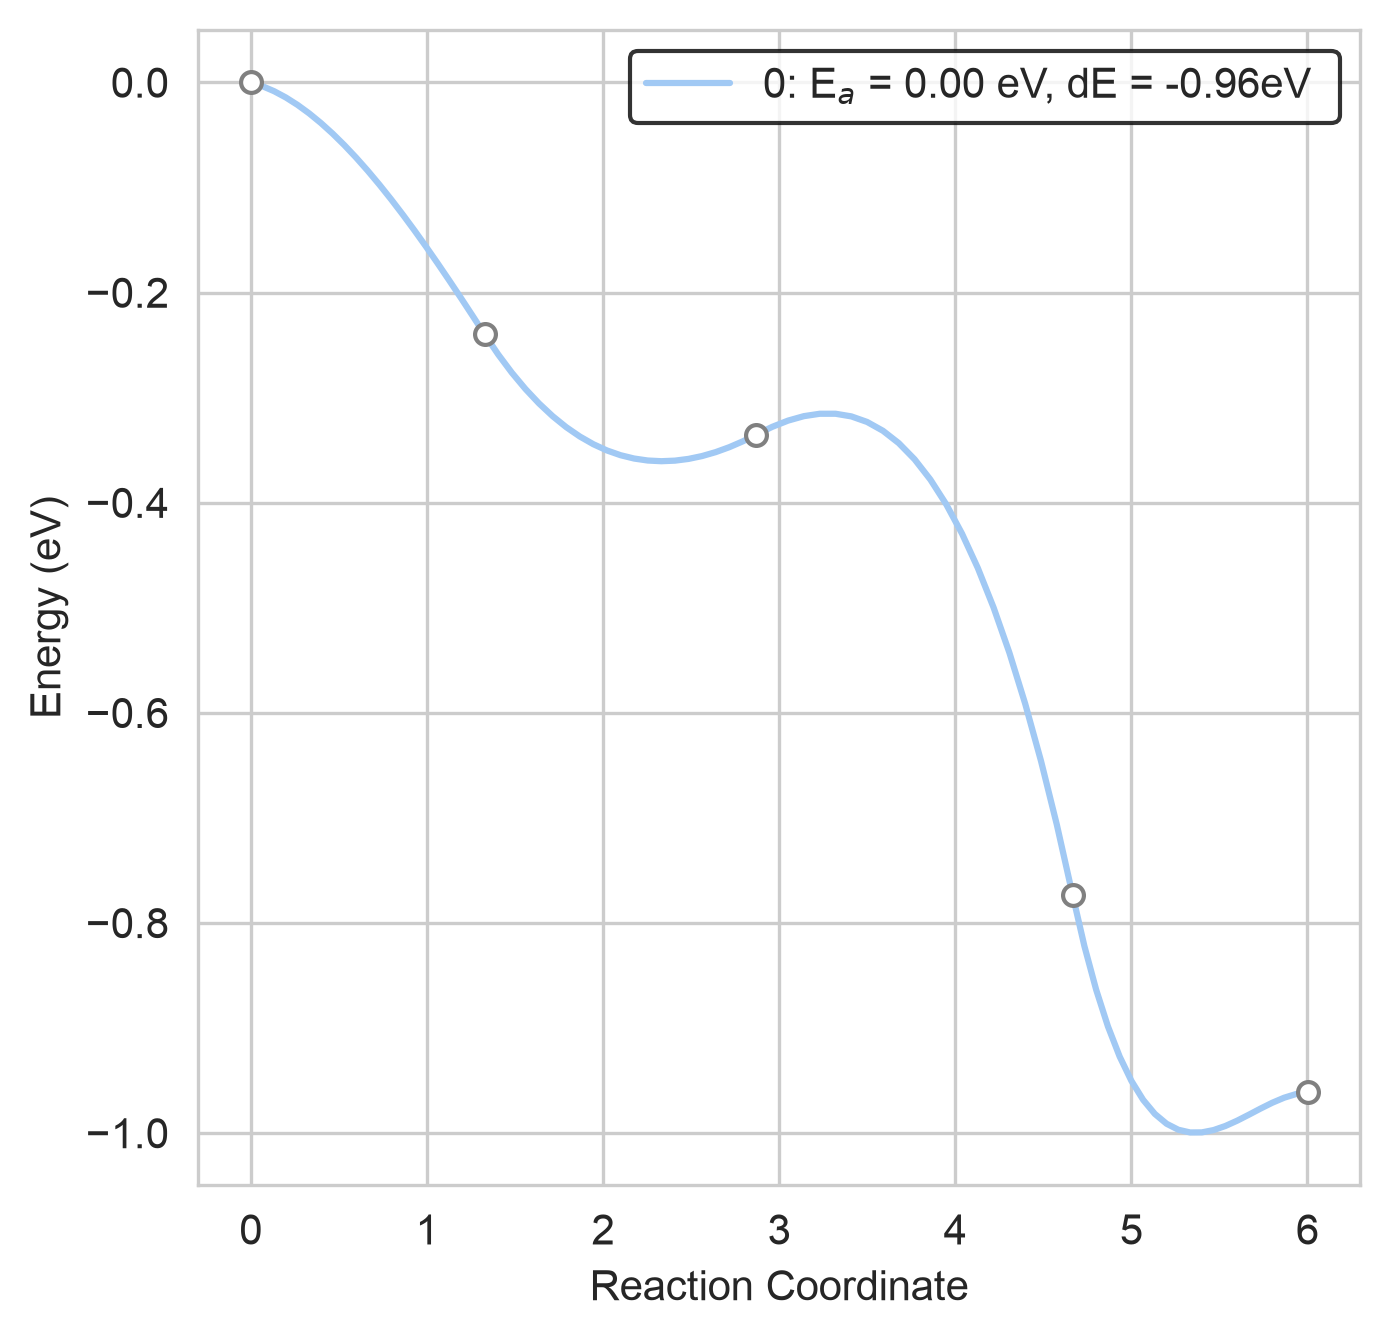

In [16]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,**kws):
    for k,v in image_dict.items():
        fit = forcecurve.fit_images(v["images"])
        Ef = fit[1].max()
        ax.plot(fit[2],fit[3],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV ')
        ax.plot(fit[0],fit[1],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(5,5),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results.T,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
    #flat_ax[i].set_title(f"expansion={nebbys[i]["expansion"]},rattle={nebbys[i]["rattle"]},nimages={nebbys[i]["nimages"]}")
ax.legend(edgecolor="black")